In [1]:
import os
import tensorflow as tf
from tqdm import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, models
from keras.models import Sequential, Model
from loss import custom_loss
from keras.losses import MeanSquaredError
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose


import DAE_DataGenerator
import importlib

importlib.reload(DAE_DataGenerator)
from DAE_DataGenerator import OptimizedDataGenerator as DAE_DG
#from dataprep import *
from OptimizedDataGenerator_v2 import OptimizedDataGenerator as NewDG
from loss import *
import models
importlib.reload(models)
from models import CreateAutoEncoder
from models import var_network
from models import CreateModel

from dataset_utils import add_noise

import matplotlib.pyplot as plt
pi = 3.14159265359

maxval=1e9
minval=1e-9

2026-02-25 14:39:22.450410: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [21]:
'''Plot predicted output vs output'''
weights_path = './trained_models/DAE/model-b7ec2423-DAE_2bit_80eN_NoQOut_nPSNR-checkpoints/'
base_dir = weights_path
checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
#training_cp_path = os.path.join(base_dir, 'training_log.csv')
#training_history = pd.read_csv(training_cp_path)
print(f"Loading model from {latest_checkpoint}")
model=CreateAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3, decoder_filters = 64)

model.load_weights(latest_checkpoint)

tfrecords_dir_val = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/DAE_digitized_raw"
# tfrecords_dir_val = os.path.join(tfrecords_dir_val, )

test_generator = DAE_DG(
    load_from_tfrecords_dir = tfrecords_dir_val,
)

# predicts test data
p_test = model.predict(test_generator)



# weights_path2 = './trained_models/DAE/model-e4177e22-DAE_80eNoise_5filters_convTranspose-checkpoints'
# # base_dir = weights_path
# checkpoint_files2 = [os.path.join(weights_path2, f) for f in os.listdir(weights_path2) if f.endswith('.hdf5')]
# latest_checkpoint2 = max(checkpoint_files2, key=os.path.getmtime)
# #training_cp_path = os.path.join(base_dir, 'training_log.csv')
# #training_history = pd.read_csv(training_cp_path)
# print(f"Loading model from {latest_checkpoint2}")
# model2=CreateAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3)

# model2.load_weights(latest_checkpoint2)

# tfrecords_dir_val = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/DAE"
# # tfrecords_dir_val = os.path.join(tfrecords_dir_val, )

# test_generator2 = DAE_DG(
#     load_from_tfrecords_dir = tfrecords_dir_val,
# )

# # predicts test data
# p_test2 = model2.predict(test_generator2)


Loading model from ./trained_models/DAE/model-b7ec2423-DAE_2bit_80eN_NoQOut_nPSNR-checkpoints/weights.04-t-19.4733-v-19.5132.hdf5
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/DAE_digitized_raw/metadata.json


21/21 [==============================] - 4s 175ms/step


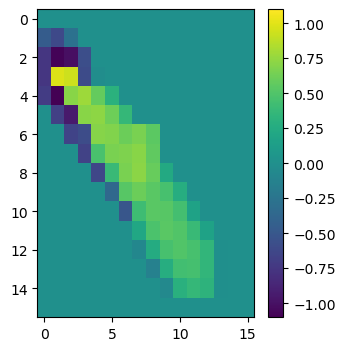

In [4]:
# plt.imshow(p_test[0,:, :,0], vmin = -1.1, vmax = 1.1)
fig = plt.figure(figsize = (3.5, 4))
plt.imshow(test_generator[0][1][50, :, :,0], vmin = -1.1, vmax = 1.1, aspect='auto'),
plt.colorbar()

(100, 16, 16, 2)
input_6
4/4 [==============================] - 0s 2ms/step
q_separable_conv2d_5
4/4 [==============================] - 0s 2ms/step
average_pooling2d_10
4/4 [==============================] - 0s 2ms/step
q_conv2d_5
4/4 [==============================] - 0s 2ms/step
average_pooling2d_11
4/4 [==============================] - 0s 4ms/step
conv2d_transpose_10
4/4 [==============================] - 0s 3ms/step
conv2d_transpose_11
4/4 [==============================] - 0s 3ms/step
conv2d_5
4/4 [==============================] - 0s 4ms/step


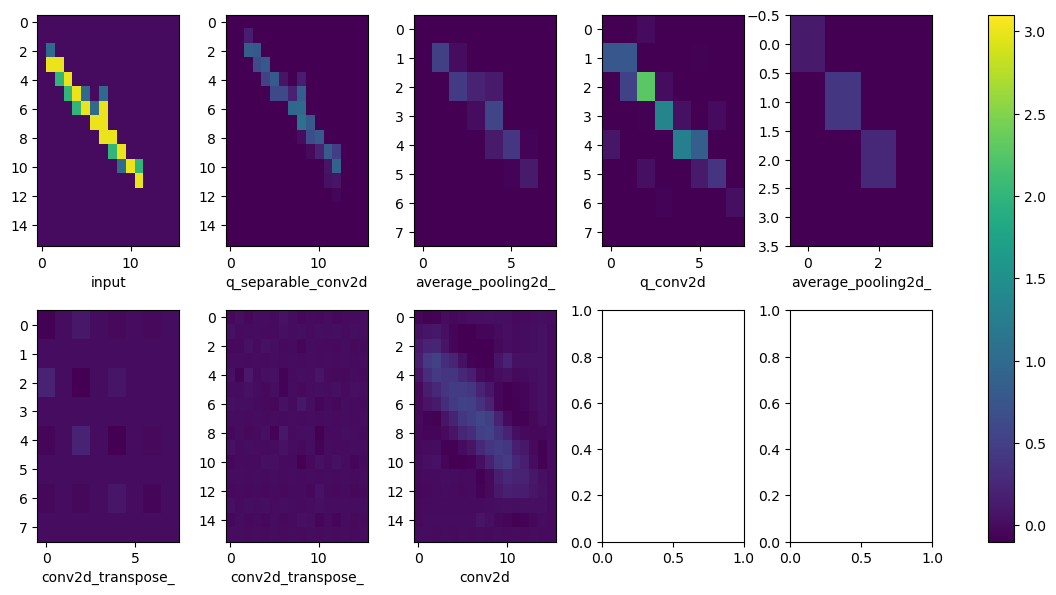

In [24]:
from keras import Model

N = 50
test_cluster = test_generator[0][0][:100][:,:,:]
print(test_cluster.shape)
#indicies: batch_index, in/out, index_in_batch, {nxm pixels}, time slice

layer_substrings = ['inp','conv', 'pool', 'samp']

kernel = 0


# for k in range(8):
i=0
fig, ax = plt.subplots(2, 5, figsize=(12,6))
ax = ax.flatten()
for layer in model.layers:
    if any(substring in layer.name for substring in layer_substrings):
        print(layer.name)
        layer_name =layer.name
        int_model = Model(inputs=model.input, outputs=model.get_layer(layer_name).output)
        out = int_model.predict(test_cluster)
        if len(out[N][0,0,:])>2:
            cluster = out[N][:,:, kernel]
        else:
            cluster = out[N][:,:,1]
        a = ax[i].imshow(cluster, vmin = -0.1, vmax = 3.1, aspect='auto')
        ax[i].set(xlabel = layer_name[:-2])
        i+=1
        # plt.colorbar(a)
    else: 
        continue
fig.tight_layout()
fig.colorbar(a, ax = ax, orientation = 'vertical',)
    # fig.suptitle(f'ConvTranspose DAE, conv_kernel {k}', y=1.04)
    # plt.savefig(os.path.join(weights_path, f'ConvTranspose_DAE_byLayer_kernel{k}.png'))


# fig.show()

# for layer in model.layers:
#     name = layer.name
#     # outputs = model.get_layer(name).output
#     print(name)

# intermediate_layer_model = Model(inputs=model.input,
#                                  outputs=model.get_layer(layer_name).output)
# print(model.get_layer('up_sampling2d').output)




# # Testing
# # test = np.random.random(input_shape)[np.newaxis,...x]
# layer_outs = [func([test_generator, 1.]) for func in functors]
# print(layer_outs)

0.011001471
0.010153989
0.02750978


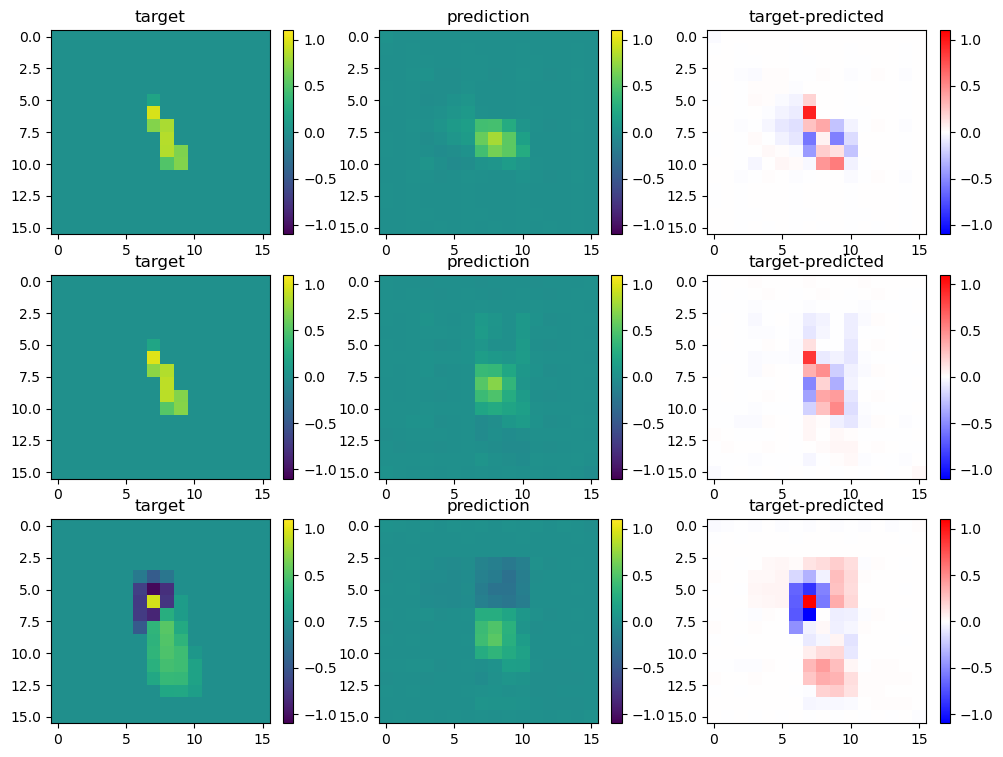

In [25]:
# from keras import Model

N = 18
fig, ax = plt.subplots(3, 3, figsize=(12,9))

a=ax[0,1].imshow(p_test[N,:, :,0], vmin = -1.1, vmax = 1.1,aspect='auto')
ax[0,1].set(title = 'prediction')
fig.colorbar(a, ax = ax[0,1], orientation = 'vertical',)

a=ax[0,0].imshow(test_generator[0][1][N, :, :,0], vmin = -1.1, vmax = 1.1, aspect='auto')
ax[0,0].set(title = 'target')
fig.colorbar(a, ax = ax[0,0], orientation = 'vertical',)

a=ax[0,2].imshow(test_generator[0][1][N, :, :,0]-p_test[N,:, :,0], vmin = -1.1, vmax = 1.1, aspect='auto', cmap='bwr')
ax[0,2].set(title = 'target-predicted')
fig.colorbar(a, ax = ax[0,2], orientation = 'vertical',)

print(np.mean((test_generator[0][1][N, :, :,0]-p_test[N,:, :,0])**2, axis= (0,1)))



a=ax[1,1].imshow(p_test2[N,:, :,1], vmin = -1.1, vmax = 1.1,aspect='auto')
ax[1,1].set(title = 'prediction')
fig.colorbar(a, ax = ax[1,1], orientation = 'vertical',)

a=ax[1,0].imshow(test_generator2[0][1][N, :, :,1], vmin = -1.1, vmax = 1.1, aspect='auto')
ax[1,0].set(title = 'target')
fig.colorbar(a, ax = ax[1,0], orientation = 'vertical',)

a=ax[1,2].imshow(test_generator2[0][1][N, :, :,1]-p_test2[N,:, :,1], vmin = -1.1, vmax = 1.1, aspect='auto', cmap='bwr')
ax[1,2].set(title = 'target-predicted')
fig.colorbar(a, ax = ax[1,2], orientation = 'vertical',)

print(np.mean((test_generator2[0][1][N, :, :,1]-p_test2[N,:, :,1])**2, axis= (0,1)))



a=ax[2,1].imshow(p_test2[N,:, :,0], vmin = -1.1, vmax = 1.1,aspect='auto')
ax[2,1].set(title = 'prediction')
fig.colorbar(a, ax = ax[2,1], orientation = 'vertical',)

a=ax[2,0].imshow(test_generator2[0][1][N, :, :,0], vmin = -1.1, vmax = 1.1, aspect='auto')
ax[2,0].set(title = 'target')
fig.colorbar(a, ax = ax[2,0], orientation = 'vertical',)

a=ax[2,2].imshow(test_generator2[0][1][N, :, :,0]-p_test2[N,:, :,0], vmin = -1.1, vmax = 1.1, aspect='auto', cmap='bwr')
ax[2,2].set(title = 'target-predicted')
fig.colorbar(a, ax = ax[2,2], orientation = 'vertical',)

print(np.mean((test_generator2[0][1][N, :, :,0]-p_test2[N,:, :,0])**2, axis= (0,1)))
# print(test_generator[0][1][:, :, :,1].shape)
# print(p_test[:,:, :,0].shape)
# pull = test_generator[0][1][:, :, :,1]-p_test[4999,:, :,0]
# bins = np.linspace(-1.2,1.2,20)
# ax[1,1].hist(pull.numpy().flatten(), color = 'k',bins=bins, histtype='step', )
# ax[1,1].set(title = 'residual')


#indicies: batch_index, in/out, index_in_batch, {nxm pixels}, time slice

# layer_substrings = ['inp','conv', 'pool', 'samp']

# kernel = 5


# # for k in range(8):
# i=0
# ax = ax.flatten()
# for layer in model.layers:
#     if any(substring in layer.name for substring in layer_substrings):
#         print(layer.name)
#         layer_name =layer.name
#         int_model = Model(inputs=model.input, outputs=model.get_layer(layer_name).output)
#         out = int_model.predict(test_cluster)
#         if len(out[N][0,0,:])>2:
#             cluster = out[N][:,:, kernel]
#         else:
#             cluster = out[N][:,:,0]
#         a = ax[i].imshow(cluster, vmin = -1.1, vmax = 1.1, aspect='auto')
#         ax[i].set(xlabel = layer_name[:-2])
#         i+=1
#         # plt.colorbar(a)
#     else: 
#         continue
#     fig.tight_layout()
#     fig.colorbar(a, ax = ax, orientation = 'vertical',)
    # fig.suptitle(f'ConvTranspose DAE, conv_kernel {k}', y=1.04)
    # plt.savefig(os.path.join(weights_path, f'ConvTranspose_DAE_byLayer_kernel{k}.png'))


# fig.show()

# for layer in model.layers:
#     name = layer.name
#     # outputs = model.get_layer(name).output
#     print(name)

# intermediate_layer_model = Model(inputs=model.input,
#                                  outputs=model.get_layer(layer_name).output)
# print(model.get_layer('up_sampling2d').output)




# # Testing
# # test = np.random.random(input_shape)[np.newaxis,...x]
# layer_outs = [func([test_generator, 1.]) for func in functors]
# print(layer_outs)

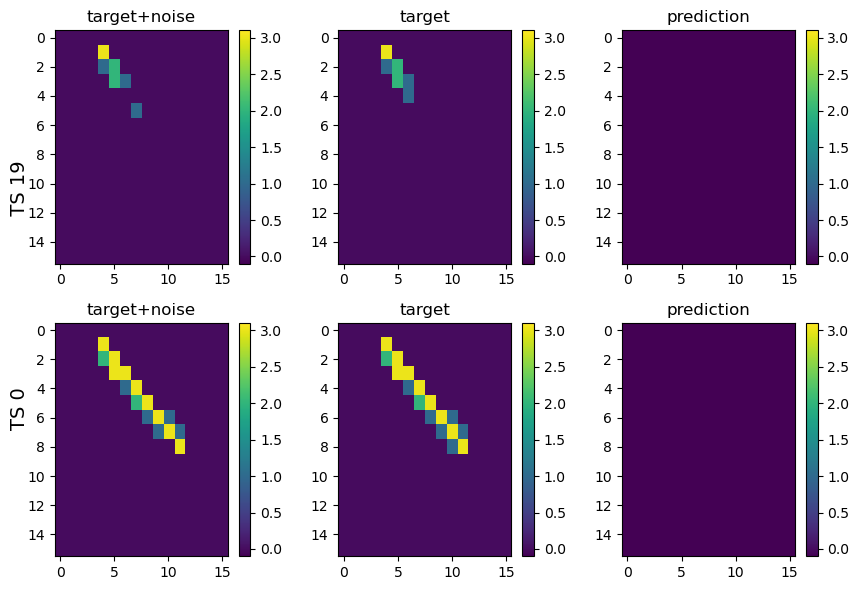

In [19]:
# from keras import Model

N = 29
fig, ax = plt.subplots(2, 3, figsize=(9,6))
ts = [0,1]
vmin, vmax = [-0.1, 3.1]

for i, t in enumerate(ts):

    a=ax[i,2].imshow(3*p_test[N,:, :,t], vmin = vmin, vmax = vmax, aspect='auto')
    ax[i,2].set(title = 'prediction')
    fig.colorbar(a, ax = ax[i,2], orientation = 'vertical',)
    
    a=ax[i,0].imshow(test_generator[0][0][N, :, :,t], vmin = vmin, vmax = vmax, aspect='auto')
    ax[i,0].set(title = 'target+noise')
    fig.colorbar(a, ax = ax[i,0], orientation = 'vertical',)
    
    a=ax[i,1].imshow(test_generator[0][1][N, :, :,t], vmin = vmin, vmax = vmax, aspect='auto', #cmap='bwr'
                    )
    ax[i,1].set(title = 'target')
    fig.colorbar(a, ax = ax[i,1], orientation = 'vertical',)

fig.supylabel('TS 0                            TS 19'
              , x=0.05, fontsize=14)
fig.tight_layout()
# fig.suptitle
    
    # print(np.mean((test_generator[i][1][N, :, :,0]-p_test[N,:, :,0])**2, axis= (0,1)))


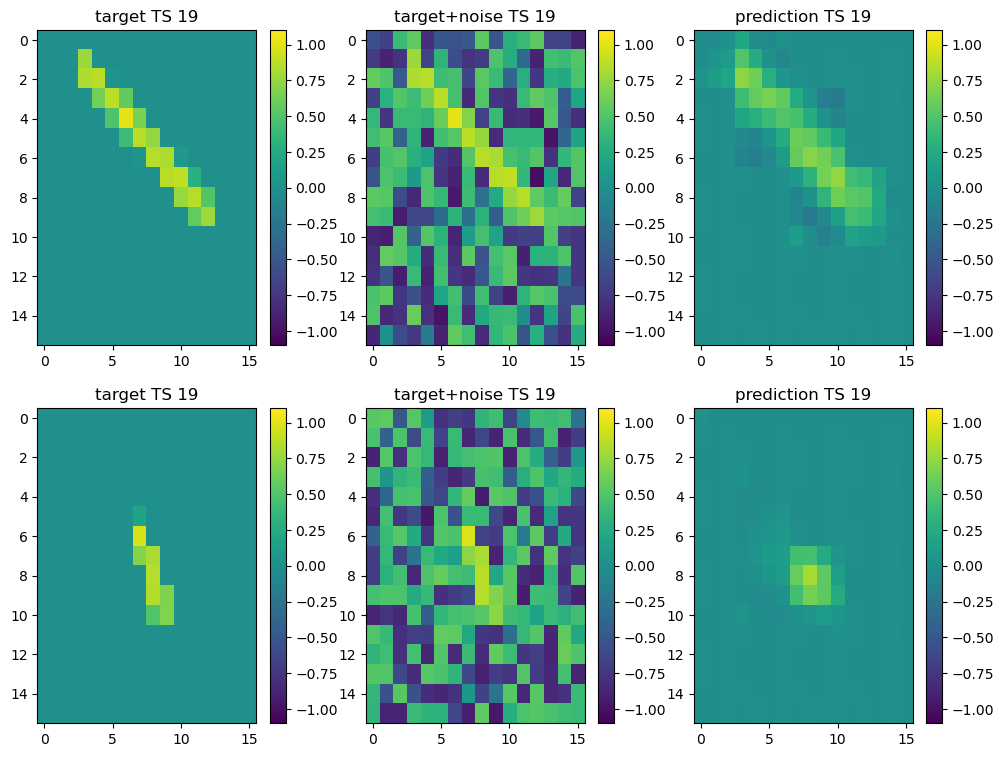

In [12]:
from keras import Model

N = 16
fig, ax = plt.subplots(2, 3, figsize=(12,9))

a=ax[0,2].imshow(p_test[N,:, :,0], vmin = -1.1, vmax = 1.1,aspect='auto')
ax[0,2].set(title = 'prediction TS 19')
fig.colorbar(a, ax = ax[0,2], orientation = 'vertical',)

a=ax[0,0].imshow(test_generator[0][1][N, :, :,0], vmin = -1.1, vmax = 1.1, aspect='auto')
ax[0,0].set(title = 'target TS 19')
fig.colorbar(a, ax = ax[0,0], orientation = 'vertical',)

a=ax[0,1].imshow(test_generator[0][0][N, :, :,0], vmin = -1.1, vmax = 1.1, aspect='auto')
ax[0,1].set(title = 'target+noise TS 19')
fig.colorbar(a, ax = ax[0,1], orientation = 'vertical',)


M = 18
a=ax[1,2].imshow(p_test[M,:, :,0], vmin = -1.1, vmax = 1.1,aspect='auto')
ax[1,2].set(title = 'prediction TS 19')
fig.colorbar(a, ax = ax[1,2], orientation = 'vertical',)

a=ax[1,0].imshow(test_generator[0][1][M, :, :,0], vmin = -1.1, vmax = 1.1, aspect='auto')
ax[1,0].set(title = 'target TS 19')
fig.colorbar(a, ax = ax[1,0], orientation = 'vertical',)

a=ax[1,1].imshow(test_generator[0][0][M, :, :,0], vmin = -1.1, vmax = 1.1, aspect='auto')
ax[1,1].set(title = 'target+noise TS 19')
fig.colorbar(a, ax = ax[1,1], orientation = 'vertical',)

In [2]:
from scipy.optimize import curve_fit

def gauss(x, A, mu, sigma):
    return A * np.exp(-(x - mu) ** 2 / (2 * sigma ** 2))

def pull_plot(ax, var, name, label, p=0):
    
    h = ax.hist(df[var],bins=np.linspace(-5,5,50),histtype='step', label=label)
    ax.set_xlabel(name)
    ax.set_yscale('log')

    ydata = h[0]
    xdata = h[1][:-1]+3/50.

    pars, cov = curve_fit(gauss,xdata,ydata)

    xbins = np.linspace(-5,5,100)
    ax.plot(xbins,gauss(xbins,pars[0],pars[1],pars[2]),color='black')
    ax.set_ylim(0.5,100000)

    print('Mean',pars[1])
    print('Sigma',pars[2])

    if p:
        ax.text(-1,25,"$\mu$="+str(round(pars[1],2)))
        ax.text(-1,10,"$\sigma$="+str(round(abs(pars[2]),2)))

In [24]:
def residual_plot(ax, thisdf, var1, var2, name, label, scaling=1.0,color = 'blue'):
    
    nbins = 15
    
    var1_scaled = thisdf[var1] * scaling
    var2_scaled = thisdf[var2] * scaling
    residual_scaled = var1_scaled - var2_scaled
    
    xmin = np.min(var1_scaled)
    xmax = np.max(var1_scaled)
    
    step = 1.0*(xmax-xmin)/nbins
    
    x = sns.regplot(x=var1_scaled, y=residual_scaled, x_bins=np.linspace(xmin,xmax,nbins), fit_reg=None, marker='.', ax=ax, label=label, color = color)
    ax.set_xlabel('True ' + name)
    ax.set_ylabel('True - predicted ' + name)
    
    thisdf['residual'+var2] = residual_scaled
    # print(var1)
    
    means = []
    upbar = []
    downbar = []
    for i in range(0,nbins):
        means += [np.mean(thisdf['residual'+var2][(var1_scaled>xmin + i*step) & (var1_scaled<xmin + (i+1)*step)])]
        upbar += [means[i] + np.mean(thisdf['sigma'+var2][(var1_scaled>xmin + i*step) & (var1_scaled<xmin + (i+1)*step)] * scaling)]
        downbar += [means[i] - np.mean(thisdf['sigma'+var2][(var1_scaled>xmin + i*step) & (var1_scaled<xmin + (i+1)*step)] * scaling)]
    ax.fill_between(x=np.linspace(xmin,xmax,nbins),y1=upbar,y2=downbar, alpha=0.2, color = color)
    print(f"{name} spread: ",np.mean(np.array(upbar)-np.array(downbar)))
    
def inverse_cot(cota):
    a = np.arctan(1.0/cota)
    a[np.where(a<0)] = a[np.where(a<0)] + pi
    return a    

def residual_plot_deg(ax, thisdf, var1, var2, name, label, scaling=1.0, color = 'blue'):
    # positions
    if 'cot' not in var1:
        residual_plot(ax, thisdf, var1, var2, name, label=label, scaling=scaling)
        return

    thisdf['angle'] = inverse_cot(thisdf[var2].values * scaling)*180/pi
    
    thisdf['angleup'] = abs(inverse_cot((thisdf[var2].values + thisdf['sigma'+var2].values) * scaling)*180/pi - thisdf['angle'])
    thisdf['angledown'] = abs(inverse_cot((thisdf[var2].values - thisdf['sigma'+var2].values) * scaling)*180/pi - thisdf['angle'])
    thisdf['angletrue'] = inverse_cot(thisdf[var1].values * scaling)*180/pi
        
    var1 = 'angletrue'
    var2 = 'angle'
    
    nbins = 15
    xmin = np.min(thisdf[var1])
    xmax = np.max(thisdf[var1])
    
    step = 1.0*(xmax-xmin)/nbins
        
    x = sns.regplot(x=thisdf[var1], y=(thisdf[var1]-thisdf[var2]), x_bins=np.linspace(xmin,xmax,nbins), fit_reg=None, marker='.', ax=ax, label=label, color = color)
    ax.set_xlabel('True ' + name)
    ax.set_ylabel('True - predicted ' + name)
    
    thisdf['residual'+var2] = (thisdf[var1]-thisdf[var2])
    # print(var1)
    
    means = []    
    upbar = []
    downbar = []
    for i in range(0,nbins):
        means += [np.mean(thisdf['residual'+var2][(thisdf[var1]>xmin + i*step) & (thisdf[var1]<xmin + (i+1)*step)])]
        upbar += [means[i] + np.mean(thisdf['angleup'][(thisdf[var1]>xmin + i*step) & (thisdf[var1]<xmin + (i+1)*step)])]
        downbar += [means[i] - np.mean(thisdf['angledown'][(thisdf[var1]>xmin + i*step) & (thisdf[var1]<xmin + (i+1)*step)])]
    #ax.scatter(x=np.linspace(xmin,xmax,nbins),y=means)
    ax.fill_between(x=np.linspace(xmin,xmax,nbins),y1=upbar,y2=downbar, alpha=0.2, color = color)
    print(f"{name} spread: ",np.mean(np.array(upbar)-np.array(downbar)))

Loading model from ./trained_models/DAE_regression/model-8d931875-DAE_regression_opt2bit-checkpoints/weights.740-t-7598.08-v-7873.52.hdf5
q_activation_55
Model: "model_18"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_7 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 q_separable_conv2d_6 (QSepa  (None, 16, 16, 5)        33        
 rableConv2D)                                                    
                                                                 
 q_activation_52 (QActivatio  (None, 16, 16, 5)        0         
 n)                                                              
                                                                 
 average_pooling2d_12 (Avera  (None, 8, 8, 5)          0         
 gePooling2D)                                                    
                                    

21/21 [==============================] - 4s 147ms/step


100%|██████████| 21/21 [00:02<00:00, 10.35it/s]


DAE_regression
$x$ [um] spread:  25.031013
$y$ [um] spread:  7.1754303


/tmp/ipykernel_608/1322428532.py:32: RuntimeWarning: divide by zero encountered in divide
  a = np.arctan(1.0/cota)


...

OG_regression
$x$ [um] spread:  26.507692
$y$ [um] spread:  6.7516108


/tmp/ipykernel_608/1322428532.py:32: RuntimeWarning: divide by zero encountered in divide
  a = np.arctan(1.0/cota)


$\alpha$ [deg] spread:  67.46513


/tmp/ipykernel_608/1322428532.py:32: RuntimeWarning: divide by zero encountered in divide
  a = np.arctan(1.0/cota)


$\beta$ [deg] spread:  32.226887


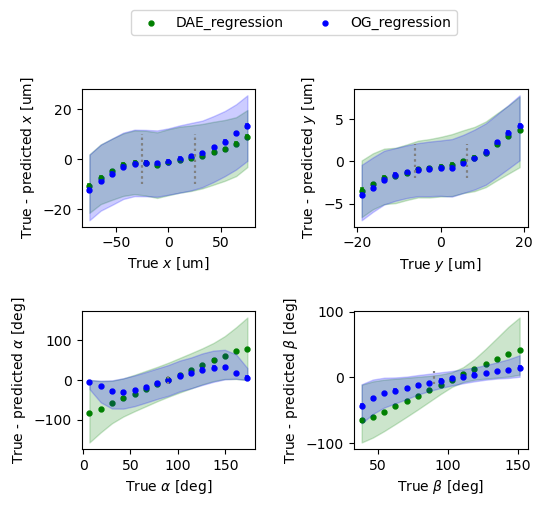

In [27]:
#Create Plots
# t0s=[0,3,6,9]
# 
weights = [
            # './trained_models/model-aa3c9320-3src_2TS_OG-checkpoints',
            # './trained_models/model-e64ce838-3src_80eNoise-checkpoints',
            # './trained_models/model-c30dd8d2-3sr16x16__NoNoise-checkpoints/',
            # './trained_models/DAE_regression/model-b49a50a4-DAE_regression_64DecodeFilters_Dense16-checkpoints/',
            # './trained_models/model-1be2e7e1-400eThresh_80eNoise-checkpoints',
            './trained_models/DAE_regression/model-8d931875-DAE_regression_opt2bit-checkpoints',
            './trained_models/model-f8e99d99-3sr16x16_opt2Bit_80eNoise-checkpoints'
            
            # './trained_models/model-c8f8bb70-3sr16x16_2TS_80eNoise-checkpoints/',
          ]
tfrs = [
        # 'TFR_val/2TS_OG',
        # 'TFR_val/3src_80eNoise', 
        # "TFR_val/3sr_16x16_NoNoise",       
        # "TFR_val/3sr_16x16_80eNoise",
        # 'TFR_val/3sr_16x16_80eN_400eT',
        'TFR_val/3sr_16x16_Opt2bit',
        'TFR_val/3sr_16x16_Opt2bit'
        # "TFR_val/3sr_16x16_80eNoise",
        ]
dense = [
            # None,
         16, 
         None, 
         ]
labels = [
          # 'No Noise', 
          'DAE_regression',
          'OG_regression'
          # 'DAE-16Dense_64DecodeFilters',
          # '80e Noise + 400e Thresh', 
          # '80e Noise', 
          # ,
          # 'DAE-Dense 32', 'DAE-Dense 64'
          ]
colors = ['green', 'blue']

# p=[0,1]

nl = int(len(weights))

# fig, axes = plt.subplots(2,2,sharex=True,sharey=True,figsize=(6,5))
fig1, axes1 = plt.subplots(2,2,figsize=(6,5))
# fig1, axes1 = plt.subplots(1, 1, figsize=(5,4))
fig1.tight_layout(pad=4.0)

for i in range(nl):
    # base_dir = f'./weights-200ps_'+str(t0)
    base_dir = weights[i]
    checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
    latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
    #training_cp_path = os.path.join(base_dir, 'training_log.csv')
    #training_history = pd.read_csv(training_cp_path)
    print(f"Loading model from {latest_checkpoint}")

    if dense[i] is not None:
        DAE=CreateAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3, decoder_filters = 64)
        layer_name = DAE.layers[8].name
        print(layer_name)
        encoder = Model(inputs=DAE.input, outputs=DAE.get_layer(layer_name).output)
        encoder.trainable = False
        x_in = encoder.input
        lat_shape = encoder.output.shape
        dense_net = var_network(encoder.output, hidden=dense[i], output=14)
        model = Model(inputs=x_in, outputs=dense_net)
    else:
        model=CreateModel((16,16,2),n_filters=5,pool_size=3,conv_kernel_size=3
                          # mean_filter=mean_filter[i], thresh = thresh[i]
                         )

    model.load_weights(latest_checkpoint)
    model.summary()
    
    tfrecords_dir_val = "/uscms/home/bweiss/nobackup/smart-pixels/tfrecords/"+tfrs[i]
    test_generator = NewDG(
        load_from_tfrecords_dir = tfrecords_dir_val,
    )
    # print(test_generator[0][0][:,:,:])

    # predicts test data
    p_test = model.predict(test_generator)
    
    complete_truth = None
    for _, y in tqdm(test_generator):
            if complete_truth is None:
                complete_truth = y
            else:
                complete_truth = np.concatenate((complete_truth, y), axis=0)
    
    # creates df with all predicted values and matrix elements - 4 predictions, all 10 unique matrix elements
    df = pd.DataFrame(p_test,columns=['x','M11','y','M22','cotA','M33','cotB','M44','M21','M31','M32','M41','M42','M43'])

    # df['x'] = df['x']*75.0
    # df['y'] = df['y']*18.75
    
    # stores all true values in same matrix as xtrue, ytrue, etc.
    df['xtrue'] = complete_truth[:,0]
    df['ytrue'] = complete_truth[:,1]
    df['cotAtrue'] = complete_truth[:,2]
    df['cotBtrue'] = complete_truth[:,3]
    df['M11'] = minval+tf.math.maximum(df['M11'], 0)
    df['M22'] = minval+tf.math.maximum(df['M22'], 0)
    df['M33'] = minval+tf.math.maximum(df['M33'], 0)
    df['M44'] = minval+tf.math.maximum(df['M44'], 0)
    
    df['sigmax'] = abs(df['M11'])
    df['sigmay'] = np.sqrt(df['M21']**2 + df['M22']**2)
    df['sigmacotA'] = np.sqrt(df['M31']**2+df['M32']**2+df['M33']**2)
    df['sigmacotB'] = np.sqrt(df['M41']**2+df['M42']**2+df['M43']**2+df['M44']**2)
    
    # calculates residuals for x, y, cotA, cotB
    residuals = df['xtrue'] - df['x']
    residualsy = df['ytrue'] - df['y']
    residualsA = df['cotAtrue'] - df['cotA']
    residualsB = df['cotBtrue'] - df['cotB']
    
    df['pullx'] = (df['xtrue']-df['x'])/df['sigmax']
    df['pully'] = (df['ytrue']-df['y'])/df['sigmay']
    df['pullcotA'] = (df['cotAtrue']-df['cotA'])/df['sigmacotA']
    df['pullcotB'] = (df['cotBtrue']-df['cotB'])/df['sigmacotB']

    ### Residual Plots ###
    print(labels[i])
    residual_plot(axes1[0][0],df,'xtrue','x',r'$x$ [um]', labels[i], scaling=75.0, color = colors[i])
    axes1[0][0].plot([-25,-25],[-10,10],color='gray',linestyle=':')
    axes1[0][0].plot([25,25],[-10,10],color='gray',linestyle=':')
    residual_plot(axes1[0][1],df,'ytrue','y',r'$y$ [um]', labels[i], scaling=18.75, color = colors[i])
    axes1[0][1].plot([-6.25,-6.25],[-2,2],color='gray',linestyle=':')
    axes1[0][1].plot([6.25,6.25],[-2,2],color='gray',linestyle=':')
    residual_plot_deg(axes1[1][0],df,'cotAtrue','cotA',r'$\alpha$ [deg]', labels[i], scaling=8.0, color = colors[i])
    axes1[1][0].plot([90,90],[-10,10],color='gray',linestyle=':')
    residual_plot_deg(axes1[1][1],df,'cotBtrue','cotB',r'$\beta$ [deg]', labels[i], scaling=1.7, color = colors[i])
    axes1[1][1].plot([90,90],[-10,10],color='gray',linestyle=':')    
    save_fig_path = os.path.join(base_dir, 'summary1.png')
    
    # residual_plot_deg(axes1,df,'cotAtrue','cotA',r'$\alpha$ [deg]', labels[i], scaling=8.0)
    # axes1.plot([90,90],[-10,10],color='gray',linestyle=':')
# print("done!")
nl = int(len(weights))
lines_labels = [ax.get_legend_handles_labels() for ax in fig1.axes]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)]
lgd = fig1.legend(lines[:nl], labels[:nl], bbox_to_anchor=(0.5, 1.05), loc='upper center', ncol=2)
plt.savefig(save_fig_path, bbox_extra_artists=(lgd,), bbox_inches='tight')


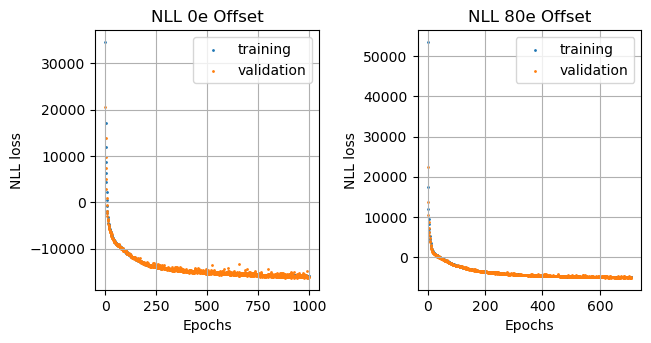

In [3]:
base_dirs = [
    # './trained_models/model-b0ae67c9-2TS_OG-checkpoints',
    # './trained_models/model-a86fd471-80eNoise-checkpoints'
    # './trained_models/model-1bff7ad4-2s_OG-checkpoints'
    # './trained_models/model-372eef38-3src_MFT3_133e_Kernel5-checkpoints',
    # './trained_models/DAE/model-422f68a2-DAE_2bit_80eN_NoQOut_SSIM-checkpoints',
    './SQ_DAE_regression/model-9017f974-SQDAE_regression-checkpoints/',
    './SQ_DAE_regression/model-2e56fcfd-SQDAE_regression_80eThreshOffset-checkpoints/'
]

titles = [
    # 'No Noise',
    # '80e Noise',
    # '3x3 Mean Filter+ 133e Thresh'
    # 'MF3_T133 5x5 kernel size'
    # '5 Decoding filters', '32 decoding filters'
    'NLL 0e Offset', 'NLL 80e Offset'
]

fig, ax =  plt.subplots(1,2, figsize = (7,4))
plt.tight_layout(pad=4) 

ax = ax.flatten()

for i, base_dir in enumerate(base_dirs):
    # checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
    # latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
    training_cp_path = os.path.join(base_dir, 'training_log.csv')
    training_history = pd.read_csv(training_cp_path)
   
    ax[i].scatter(training_history['epoch'], training_history['loss'], s=1)
    ax[i].scatter(training_history['epoch'], training_history['val_loss'], s=1)
    ax[i].legend(['training', 'validation'])
    ax[i].grid(True)
    ax[i].set_xlabel('Epochs')
    ax[i].set_ylabel('NLL loss')
    ax[i].set_title(titles[i])

ax[1].set_ylabel('NLL loss')

plt.savefig(os.path.join(base_dir,'training_hist_NLL_0eVs80e.png'))
plt.show()